# TurtleBot kinematics

A TurtleBot is a small differential-drive robot: two driven wheels on one axle and caster balls that keep it level. In this assignment you derive how such a robot moves, answer short questions about the model, and test it against a physics simulation.

**What you need to know.** The Background section below gives everything the questions use. You do not need any kinematics beyond it. Lynch and Park, *Modern Robotics*, covers the same material in more depth. Read it if a question is unclear:

- Chapter 2: section 2.1 (degrees of freedom), section 2.3 (configuration space) and section 2.4 (velocity constraints). You can [download chapter 2 as a PDF](https://artifacts.aegeanai.com/pdf/lynch-mr/config-space.pdf).
- Chapter 3: section 3.1 (rigid-body motions in the plane). You can [download chapter 3 as a PDF](https://artifacts.aegeanai.com/pdf/lynch-mr/body-motions.pdf).
- Chapter 13: subsection 13.3.1.2 (the differential-drive robot) and section 13.4 (odometry). You can [download chapter 13 as a PDF](https://artifacts.aegeanai.com/pdf/lynch-mr/wheeled-robots.pdf).
- For Question 4: the section [from velocity to motion](https://aegean.ai/aiml-common/lectures/motion-algebras/motion-representations#from-velocity-to-motion) in motion representations, where a pose is a matrix in SE(2) and a twist is a matrix in se(2).

**How it works.** Questions 1 to 5 are written. Question 4 is a short calculation, and the others ask for two or three sentences each. Questions 6 to 8 ask for a few lines of code, followed by a check cell that prints `passed`, and one sentence about what you see. Cells marked **Provided** are complete; run them without editing. If you restart the runtime, run every cell from the top again.

| Question | Topic | Points |
|---|---|---|
| 1 to 5 | Written questions | 50 |
| 6 | The kinematic model against the simulation | 15 (code 10, sentence 5) |
| 7 | The body twist of a turning robot | 15 (code 10, sentence 5) |
| 8 | Odometry | 20 (code 15, sentence 5) |

## Setup

**Provided.** The simulation runs on a CPU, so the default Colab runtime is enough. On it, the whole notebook takes about ten minutes, almost all of it simulation. If you have a GPU runtime (Runtime > Change runtime type), the simulation uses it and runs much faster. The first cell installs the simulation libraries.

In [ ]:
import importlib
import importlib.util
import site
import subprocess
import sys

if importlib.util.find_spec("newton") is None or importlib.util.find_spec("rerun") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "newton[sim]==1.6.0", "rerun-sdk==0.37.0"])
    # rerun-sdk is found through a .pth file, which Python reads only at startup, so read it now
    for path in site.getsitepackages():
        site.addsitedir(path)
    importlib.invalidate_caches()

In [ ]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import warp as wp

wp.config.log_level = wp.LOG_WARNING
import newton
import newton.viewer

RECORDINGS = Path("recordings")
RECORDINGS.mkdir(exist_ok=True)
print("simulation device:", wp.get_device())

simulation device: cuda:0


## The simulated TurtleBot

**Provided.** The robot has the geometry of a TurtleBot3 Waffle, the robot of the class repository. Its two numbers are below: in your code, write `WHEEL_RADIUS` for $r$ and `HALF_SEPARATION` for $d$. Each wheel's motor tracks a commanded angular speed. The simulation knows nothing about the kinematic model: the chassis moves only through friction at the wheel contacts.

In [ ]:
WHEEL_RADIUS = 0.033      # r, in meters
HALF_SEPARATION = 0.1435  # d, half the distance between the two wheels, in meters

The next cell builds the simulation. You do not need to read it. `simulate(...)` runs at 60 frames per second and returns the frame times, the chassis configurations $(\phi, x, y)$ and the wheel angles $(\theta_L, \theta_R)$. `test_course` is the drive used in Questions 6 and 8: straight for 4 s at $u_L = u_R = 5$ rad/s, then along an arc for 4 s at $u_L = 3$, $u_R = 5$ rad/s.

In [ ]:
# @title Provided simulation (run it; you do not need to read it) { display-mode: "form" }
R, D = WHEEL_RADIUS, HALF_SEPARATION

# check tolerances, several times the values measured with the reference solutions on a CPU
GAP_TOL, HEADING_TOL = 0.04, 0.04
OMEGA_TOL, V_TOL, VBY_TOL = 0.02, 0.01, 0.01
ODO_TOL = 0.03


def test_course(t):
    # wheel speeds (u_L, u_R) in rad/s at time t: straight for 4 s, then an arc to the left
    return (5.0, 5.0) if t < 4.0 else (3.0, 5.0)


def angle_diff(a, b):
    # a - b wrapped to [-pi, pi)
    return (np.asarray(a) - np.asarray(b) + np.pi) % (2 * np.pi) - np.pi


def planar_pose(body_q):
    # (phi, x, y) of a body from its Newton transform (px, py, pz, qx, qy, qz, qw).
    # Newton stores the orientation as a unit quaternion (x, y, z, w). The atan2 line
    # extracts the heading phi, the rotation about the vertical z axis.
    # You don't need to fully understand this line to answer the questions.
    px, py, _, qx, qy, qz, qw = body_q
    phi = math.atan2(2 * (qw * qz + qx * qy), 1 - 2 * (qy * qy + qz * qz))
    return phi, px, py


def build_turtlebot(mu=1.0):
    # The simulated robot: a chassis with two ball casters and two driven wheels.
    # You don't need to fully understand this function to answer the questions.
    # Loading the TurtleBot3 URDF with builder.add_urdf would also work. The robot is built here instead because
    # the URDF is a xacro file whose meshes are package:// paths that do not exist outside ROS, it carries no
    # friction or motor settings (those live in the Gazebo files), and its box casters would need retuning anyway.
    builder = newton.ModelBuilder()
    builder.default_joint_cfg.damping = 0.01
    # the chassis frame sits at the midpoint of the axle; the body extends backward to two ball casters
    chassis = builder.add_link(xform=wp.transform(p=wp.vec3(0.0, 0.0, R), q=wp.quat_identity()), label="chassis")
    slick = newton.ModelBuilder.ShapeConfig(density=400.0, mu=1e-3, gap=0.005)
    builder.add_shape_box(chassis, xform=wp.transform(p=wp.vec3(-0.064, 0.0, 0.03), q=wp.quat_identity()),
                          hx=0.133, hy=0.125, hz=0.03, cfg=slick)
    for y in (0.064, -0.064):
        builder.add_shape_sphere(chassis, xform=wp.transform(p=wp.vec3(-0.177, y, -(R - 0.01)), q=wp.quat_identity()),
                                 radius=0.01, cfg=slick)
    joints, drives = [builder.add_joint_free(chassis)], []
    tire = newton.ModelBuilder.ShapeConfig(density=600.0, mu=mu, gap=0.005)
    axle_to_y = wp.quat_from_axis_angle(wp.vec3(1.0, 0.0, 0.0), -0.5 * wp.pi)
    for name, y in (("left", D), ("right", -D)):
        wheel = builder.add_link(label=name)
        builder.add_shape_cylinder(wheel, xform=wp.transform(q=axle_to_y), radius=R, half_height=0.009, cfg=tire)
        drive = builder.add_joint_revolute(
            parent=chassis, child=wheel, parent_xform=wp.transform(p=wp.vec3(0.0, y, 0.0), q=wp.quat_identity()),
            child_xform=wp.transform(), axis=newton.Axis.Y, target_kd=5.0, damping=0.01, armature=0.002,
            effort_limit=5.0, actuator_mode=newton.JointTargetMode.VELOCITY, label=f"{name}_drive",
        )
        drives.append(drive)
        joints.append(drive)
    builder.add_articulation(joints)
    # a contact uses the larger friction of its two shapes, so the floor is slick and the tires carry the grip
    builder.add_ground_plane(cfg=newton.ModelBuilder.ShapeConfig(mu=1e-3, gap=0.005))
    return builder.finalize(), chassis, drives


def simulate(model, chassis, drives, wheel_speeds, duration, recording=None, fps=60, substeps=6):
    # Drive the robot for `duration` seconds. `wheel_speeds(t)` returns the commanded (u_L, u_R)
    # in rad/s at time t. Returns the sample times, the chassis pose (phi, x, y) at each time,
    # and the two wheel angles (theta_L, theta_R) at each time.

    # The physics engine. It knows nothing about equation 13.15: the chassis moves only because
    # the tires push on the floor through friction, so the simulation is an independent check of
    # the kinematic model. The elliptic friction cone resists sliding equally in every direction
    # along the floor, sideways as much as forward. The implicit integrator keeps the stiff wheel
    # motors stable. The remaining numbers are effort and memory budgets for the solver.
    # You don't need to fully understand this line to answer the questions.
    solver = newton.solvers.SolverMuJoCo(
        model, use_mujoco_contacts=False, disable_sensors=True, solver="newton", integrator="implicitfast",
        cone="elliptic", iterations=20, ls_iterations=50, njmax=2048, nconmax=1024,
    )
    # A step reads the current state and writes the next one, so the simulation keeps two states.
    # The control is how the code talks to the motors: it carries the commanded wheel speeds.
    # You don't need to fully understand this line to answer the questions.
    state, next_state, control = model.state(), model.state(), model.control()
    # set each body's world pose (chassis and both wheels) from the starting joint values:
    # the chassis pose and the two wheel angles. You don't need to fully understand this line to answer the questions.
    newton.eval_fk(model, model.joint_q, model.joint_qd, state)
    # Contacts are where the tires and casters touch the floor. Without them the robot would fall
    # through the floor, and without friction at them the wheels would spin in place.
    # You don't need to fully understand these lines to answer the questions.
    collision = newton.CollisionPipeline(model, rigid_contact_max=1024)
    contacts = collision.contacts()
    # Newton keeps every joint speed and joint angle in one flat array. These indices pick out the
    # two wheels, so the loop can command their speeds and read their angles.
    # You don't need to fully understand these lines to answer the questions.
    drive_dofs = [int(model.joint_qd_start.numpy()[j]) for j in drives]
    drive_coords = [int(model.joint_q_start.numpy()[j]) for j in drives]
    target = control.joint_target_qd.numpy()
    # Contact physics needs a short time step to stay stable, about 3 ms here, while the poses
    # only need recording 60 times a second. Each recorded frame therefore runs several steps.
    dt = 1.0 / fps / substeps

    def advance():
        # one recorded frame of physics. You don't need to fully understand this function to answer the questions.
        nonlocal state, next_state
        for _ in range(substeps):
            state.clear_forces()  # forces from the previous step must not add up
            collision.collide(state, contacts)  # the robot has moved, so find the contacts again
            solver.step(state, next_state, control, contacts, dt)
            state, next_state = next_state, state  # the new state becomes the current one

    # You don't need to fully understand these lines to answer the questions.
    graph = None
    if wp.get_device().is_cuda:  # on a GPU, record the substeps once and replay them each frame
        with wp.ScopedCapture() as capture:
            advance()
        graph = capture.graph

    # optional: save the run as a Rerun recording, so you can replay it in 3D and watch the robot.
    # You don't need to fully understand these lines to answer the questions.
    viewer = None
    if recording is not None:
        viewer = newton.viewer.ViewerRerun(app_id="turtlebot_" + recording.stem.replace("-", "_"),
                                           record_to_rrd=str(recording), keep_historical_data=True)
        viewer.set_model(model)

    t, times, poses, angles = 0.0, [], [], []
    for _ in range(int(duration * fps)):
        # The commanded speeds may change over time, for example to drive a curve, so they are set
        # every frame. Each motor then pushes its wheel toward the commanded speed.
        target[drive_dofs] = wheel_speeds(t)
        control.joint_target_qd.assign(target)
        wp.capture_launch(graph) if graph else advance()
        t += 1.0 / fps
        # Record the true chassis pose, which the check cells compare with your model, and the
        # wheel angles, which are what wheel encoders on a real robot would measure.
        times.append(t)
        poses.append(planar_pose(state.body_q.numpy()[chassis]))
        angles.append(state.joint_q.numpy()[drive_coords])
        if viewer is not None:
            viewer.begin_frame(t)
            viewer.log_state(state)
            viewer.end_frame()
    if viewer is not None:
        viewer.close()
    return np.array(times), np.array(poses), np.array(angles)


assert abs(angle_diff(np.pi - 0.1, -np.pi + 0.1) - (-0.2)) < 1e-12, "angle_diff must wrap across pi"
print("simulation ready")

simulation ready


## Background: how a differential drive moves

**Configuration.** Fix a world frame on the floor, with axes $\hat x$ and $\hat y$. The configuration of the chassis is $q = (\phi, x, y)$. The point $(x, y)$ is the midpoint of the axle, and the heading $\phi$ is the angle from $\hat x$ to the direction the robot faces, counterclockwise positive.

**Body frame.** Attach a second frame to the chassis at the midpoint of the axle. Its axis $\hat x_b$ points forward along the heading, and $\hat y_b$ points to the robot's left. The left wheel sits a distance $d$ to the left of the midpoint and the right wheel a distance $d$ to the right. Both wheels have radius $r$.

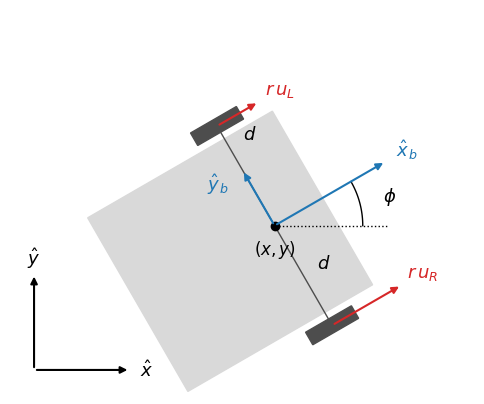

In [ ]:
# @title Provided figure { display-mode: "form" }
phi0, p0 = np.deg2rad(30), np.array([0.30, 0.18])
xb, yb = np.array([np.cos(phi0), np.sin(phi0)]), np.array([-np.sin(phi0), np.cos(phi0)])


def world(bx, by):
    # a point given in body coordinates, expressed in the world frame
    return p0 + np.multiply.outer(bx, xb) + np.multiply.outer(by, yb)


def arrow(ax, start, end, color="black", text=None, offset=(0.0, 0.0)):
    ax.annotate("", end, start, arrowprops=dict(arrowstyle="-|>", color=color, lw=1.5))
    if text:
        ax.text(*(np.asarray(end) + offset), text, color=color, fontsize=13, ha="center", va="center")


fig, ax = plt.subplots(figsize=(6, 5))
box_x, box_y = np.array([-0.197, 0.069, 0.069, -0.197]), np.array([-0.125, -0.125, 0.125, 0.125])
ax.add_patch(plt.Polygon(world(box_x, box_y), color="0.85"))
for side, label, speed in ((1, "left", 3.0), (-1, "right", 5.0)):
    wheel_x, wheel_y = np.array([-R, R, R, -R]), side * D + np.array([-0.009, -0.009, 0.009, 0.009])
    ax.add_patch(plt.Polygon(world(wheel_x, wheel_y), color="0.3"))
    center = world(0.0, side * D)
    arrow(ax, center, center + 0.02 * speed * xb, "tab:red", rf"$r\,u_{label[0].upper()}$", 0.03 * xb)
ax.plot(*world(np.array([0.0, 0.0]), np.array([-D, D])).T, color="0.3", lw=1)
arrow(ax, p0, world(0.16, 0.0), "tab:blue", r"$\hat x_b$", 0.03 * xb)
arrow(ax, p0, world(0.0, 0.08), "tab:blue", r"$\hat y_b$", -0.035 * xb)
ax.text(*world(0.03, 0.115), r"$d$", fontsize=13, ha="center", va="center")
ax.text(*world(0.03, -D / 2), r"$d$", fontsize=13, ha="center", va="center")
ax.plot(*p0, "ko")
ax.text(*(p0 + np.array([0.0, -0.035])), r"$(x, y)$", fontsize=12, ha="center")
ax.plot([p0[0], p0[0] + 0.14], [p0[1], p0[1]], "k:", lw=1)
angles = np.linspace(0.0, phi0, 20)
ax.plot(p0[0] + 0.11 * np.cos(angles), p0[1] + 0.11 * np.sin(angles), "k", lw=1)
ax.text(p0[0] + 0.135, p0[1] + 0.03, r"$\phi$", fontsize=13)
arrow(ax, (0.0, 0.0), (0.12, 0.0), text=r"$\hat x$", offset=(0.02, 0.0))
arrow(ax, (0.0, 0.0), (0.0, 0.12), text=r"$\hat y$", offset=(0.0, 0.02))
ax.set_xlim(-0.03, 0.55)
ax.set_ylim(-0.03, 0.45)
ax.set_aspect("equal")
ax.axis("off")
plt.show()

*Top view of the chassis at configuration $(\phi, x, y)$. The red arrows are the forward speeds of the two wheel centers, drawn for a robot turning left.*

**The wheels roll without slipping.** A wheel that turns at angular speed $u$ (in rad/s) moves its center forward at speed $r u$. It cannot slide sideways along its axle.

**From wheel speeds to chassis motion.** Describe the motion of the chassis by its forward speed $v$ along $\hat x_b$ and its turning rate $\omega = \dot\phi$, counterclockwise positive. A point of the chassis a distance $y_b$ to the left of the midpoint moves forward at $v - \omega y_b$: when the robot turns left, points on its left side slow down and points on its right side speed up. The left wheel is at $y_b = d$ and the right wheel at $y_b = -d$, so

$$
r u_L = v - \omega d, \qquad r u_R = v + \omega d .
$$

Adding and subtracting these two equations gives

$$
v = \frac{r\,(u_L + u_R)}{2}, \qquad \omega = \frac{r\,(u_R - u_L)}{2d} . \tag{1}
$$

Equal wheel speeds drive the robot straight. Unequal speeds turn it toward the slower wheel.

**No sideways motion.** Neither wheel center can move along $\hat y_b$, so the midpoint between them cannot either. The velocity of the axle midpoint always points along the heading.

**Body twist.** The three rates of the chassis along the body axes form the *body twist* $\mathcal{V}_b = (\omega, v_x, v_y)$: the turning rate, the forward velocity and the sideways velocity (section 3.1 of Lynch and Park). They are measured in a fixed frame that lines up with the body frame at that instant, not relative to the moving body frame, which would see the chassis at rest. For a differential drive, $v_x = v$ and $v_y = 0$.

**Odometry.** A robot cannot measure its configuration directly. Odometry estimates it from the wheel angles alone: it computes how far each wheel turned since the last reading and adds up the resulting motions step by step (section 13.4).

## Part A. Written questions (50 points)

Answer each question in the cell below it: two or three sentences, or for Question 4 the calculation and one or two sentences.

### Question 1 (10 points)

How many degrees of freedom does the TurtleBot's chassis have on a flat floor? What is its configuration space, and why is the heading a point on a circle $S^1$ rather than on the real line?

*Hint:* count the numbers you need to place the chassis on the floor; the Background lists them. For the heading, ask what happens to the robot when $\phi$ increases by $2\pi$.

*In the book:* section 2.1 shows that a coin lying on a table has three degrees of freedom ([chapter 2 PDF, pages 2 to 5](https://artifacts.aegeanai.com/pdf/lynch-mr/config-space.pdf#page=2)). Section 2.3.1 gives the C-space of a planar rigid body, such as the chassis of a mobile robot ([page 15](https://artifacts.aegeanai.com/pdf/lynch-mr/config-space.pdf#page=15)).

The chassis has 3 degrees of freedom: placing it on the floor takes three numbers, its position (x, y) and its heading $\phi$ . Its configuration space is ℝ² × S¹: ℝ² for the planar position (x, y) and S¹ for the heading  $\phi$. The heading lies on a circle because increasing $\phi$ by 2π leaves the robot in the same orientation, so $\phi$ and $\phi$ + 2π are the same configuration.

### Question 2 (10 points)

The wheels cannot slide sideways. Write this as a constraint $A(q)\dot q = 0$ with $q = (\phi, x, y)$. Why does it restrict the robot's velocities but not the configurations it can reach?

*Hint:* the robot's sideways direction is $\hat y_b = (-\sin\phi, \cos\phi)$. The sideways velocity is the dot product of $(\dot x, \dot y)$ with $\hat y_b$, and it must be zero. For the second part, think about how a driver parks a car in a space along the curb.

*In the book:* the rolling coin of section 2.4 has the same kind of constraint (Figure 2.11 and equations 2.9 and 2.10, [chapter 2 PDF, page 21](https://artifacts.aegeanai.com/pdf/lynch-mr/config-space.pdf#page=21)). The next page explains why such a constraint does not reduce the configurations the coin can reach ([page 22](https://artifacts.aegeanai.com/pdf/lynch-mr/config-space.pdf#page=22)).

The wheels can’t slide sideways, so −ẋ sin φ + ẏ cos φ = 0, i.e. A(q)q̇ = 0 with A(q) = [0, −sin φ, cos φ]. No function g(φ, x, y) has these as its derivatives, because the allowed direction changes with the heading, so the constraint is nonintegrable, i.e. nonholonomic. It limits the allowed velocities but not the reachable configurations. Like the rolling coin, the robot can reach any pose by combining forward motion and turning, as in parallel parking.

### Question 3 (10 points)

Invert equation (1): give the wheel speeds $u_L$ and $u_R$ that produce a forward speed $v$ and turning rate $\omega$. Which wheel speeds make the robot turn in place? The axle midpoint moves on a circle of signed radius $\rho = v/\omega$, positive when the robot turns left. Write $\rho$ in terms of $u_L$ and $u_R$.

*Hint:* the two wheel equations in the Background, $r u_L = v - \omega d$ and $r u_R = v + \omega d$, already relate each wheel speed to $v$ and $\omega$. For the radius, divide $v$ by $\omega$ from equation (1).

*In the book:* subsection 13.3.1.2 gives the model as equation 13.15 ([chapter 13 PDF, page 11](https://artifacts.aegeanai.com/pdf/lynch-mr/wheeled-robots.pdf#page=11)). The text right after equation 13.18 gives the wheel speeds for a given $(v, \omega)$ ([page 14](https://artifacts.aegeanai.com/pdf/lynch-mr/wheeled-robots.pdf#page=14)).

Solving r·u_L = v − ωd and r·u_R = v + ωd gives u_L = (v − ωd)/r and u_R = (v + ωd)/r. The robot turns in place (v = 0) when the wheels spin at equal and opposite speeds, u_L = −u_R. Dividing v by ω from equation (1) gives the radius ρ = v/ω = d(u_R + u_L)/(u_R − u_L), positive (a left turn) when u_R > u_L.If u_L = u_R, the robot goes straight (ρ → ∞), and if u_L = −u_R, ρ = 0 and the robot spins in place .

### Question 4 (10 points)

A TurtleBot starts at $x_0 = 2$ m, $y_0 = 1$ m with heading $\phi_0 = \pi$, so it faces the negative $\hat x$ direction. Its pose is the $SE(2)$ matrix

$$
T_0 = \begin{bmatrix} \cos\phi_0 & -\sin\phi_0 & x_0 \\ \sin\phi_0 & \cos\phi_0 & y_0 \\ 0 & 0 & 1 \end{bmatrix}.
$$

For $t = 2$ s it drives with the constant forward speed $v = 0.5$ m/s and turning rate $\omega = -\pi/4$ rad/s, and no sideways velocity. Written as a matrix in $\mathfrak{se}(2)$, its body twist is

$$
\hat\xi = \begin{bmatrix} 0 & -\omega & v \\ \omega & 0 & 0 \\ 0 & 0 & 0 \end{bmatrix}.
$$

For a constant body twist, the pose after time $t$ is $T(t) = T_0 \exp(\hat\xi t)$. With $\Delta\phi = \omega t$, the exponential has the closed form

$$
\exp(\hat\xi t) = \begin{bmatrix} \cos\Delta\phi & -\sin\Delta\phi & \dfrac{v}{\omega}\sin\Delta\phi \\ \sin\Delta\phi & \cos\Delta\phi & \dfrac{v}{\omega}(1 - \cos\Delta\phi) \\ 0 & 0 & 1 \end{bmatrix}.
$$

Compute $\exp(\hat\xi t)$ and $T(t)$, and read off the final configuration $(\phi, x, y)$. Then answer in one or two sentences: did the robot turn left or right, what path did the axle midpoint follow, and why is the product written $T_0 \exp(\hat\xi t)$ and not $\exp(\hat\xi t)\, T_0$?

*Hint:* you only need two numbers for $\exp(\hat\xi t)$: $\Delta\phi$ and $v/\omega$. In $T(t)$, the last column holds the new position, and the first column is $(\cos\phi, \sin\phi)$ of the new heading.

*In the course:* the section [from velocity to motion](https://aegean.ai/aiml-common/lectures/motion-algebras/motion-representations#from-velocity-to-motion) in motion representations writes a pose as a matrix in $SE(2)$ and a twist as a matrix in $\mathfrak{se}(2)$.

**Given.** x₀ = 2, y₀ = 1, φ₀ = π, v = 0.5, ω = −π/4, t = 2.

The parameters of the exponential

Δφ = ωt = (−π/4)(2) = −π/2

v/ω = 0.5 / (−π/4) = −2/π

Since cos(−π/2) = 0 and sin(−π/2) = −1:

```
(v/ω) sin Δφ       = (−2/π)(−1)     =  2/π
(v/ω)(1 − cos Δφ)  = (−2/π)(1 − 0)  = −2/π
```

Substituting into the closed form,

```
            ⎡ cos Δφ  −sin Δφ   (v/ω) sin Δφ      ⎤   ⎡  0   1    2/π ⎤
exp(ξ̂t) =  ⎢ sin Δφ   cos Δφ   (v/ω)(1 − cos Δφ) ⎥ = ⎢ −1   0   −2/π ⎥
            ⎣   0        0            1            ⎦   ⎣  0   0     1  ⎦
```

Since cos φ₀ = cos π = −1 and sin φ₀ = sin π = 0,

```
      ⎡ −1   0   2 ⎤
T₀ =  ⎢  0  −1   1 ⎥
      ⎣  0   0   1 ⎦
```

T(t) = T₀ exp(ξ̂t). Writing (i, j) for row i and column j:

```
(1,1) = (−1)(0)  + (0)(−1)  + (2)(0)     =  0
(1,2) = (−1)(1)  + (0)(0)   + (2)(0)     = −1
(1,3) = (−1)(2/π)+ (0)(−2/π)+ (2)(1)     =  2 − 2/π
(2,1) = (0)(0)   + (−1)(−1) + (1)(0)     =  1
(2,2) = (0)(1)   + (−1)(0)  + (1)(0)     =  0
(2,3) = (0)(2/π) + (−1)(−2/π)+ (1)(1)    =  1 + 2/π
(3,j) = (0, 0, 1)
```

Therefore

```
          ⎡ 0  −1   2 − 2/π ⎤
T(t) =    ⎢ 1   0   1 + 2/π ⎥
          ⎣ 0   0      1    ⎦
```

The upper-left block is a rotation matrix with cos φ = 0 and sin φ = 1, so φ = π/2. The last column holds the position. Hence

(φ, x, y) = (π/2, 2 − 2/π, 1 + 2/π) ≈ (1.571, 1.363, 1.637)

**Check.** φ = φ₀ + Δφ = π − π/2 = π/2.

Since ω < 0, the robot turned right (clockwise), and the axle midpoint followed a circular arc of radius |v/ω| = 2/π ≈ 0.64 m, a quarter circle of length vt = 1 m. The product is T₀ exp(ξ̂t), not exp(ξ̂t) T₀, because the twist is a body twist, measured in the robot’s own frame, so the motion is applied relative to the robot’s current pose by multiplying on the right.

### Question 5 (10 points)

Odometry estimates the robot's configuration from its wheel angles alone. Why does its error grow over time, and what do robots add to keep an accurate estimate?

*Hint:* odometry adds up one small motion per wheel reading. What happens to an error made in one step, when every later step starts from it?

*In the book:* the first paragraph of section 13.4 ([chapter 13 PDF, page 34](https://artifacts.aegeanai.com/pdf/lynch-mr/wheeled-robots.pdf#page=34)).

Odometry works by adding up small movements from the wheel readings, and each new step starts from the last estimate. So if the wheels slip or skid a little, or the integration is slightly off, that error stays in the estimate and every later step adds to it, which means the error keeps growing. To fix this, robots use other sensors like GPS, landmarks, or laser range finders, whose errors don’t build up, and they combine them with odometry using something like a Kalman filter or a particle filter.

## Part B. Experiments (50 points)

### Question 6 (15 points)

The configuration rate of the robot is $\dot q = (\dot\phi, \dot x, \dot y)$, with $\dot x$ and $\dot y$ measured in the world frame.

**Task.** Write `diff_drive_qdot(q, u_L, u_R)`, which returns $\dot q$ as an array of shape `(3,)`. Compute $v$ and $\omega$ from the wheel speeds with equation (1). Then $\dot\phi = \omega$. The velocity of the axle midpoint has magnitude $v$ and points along the heading $\phi$: split it into its $\hat x$ and $\hat y$ components. The provided `integrate` applies your function with small time steps.

*Hint:* a vector of length $v$ at angle $\phi$ from $\hat x$ has components $v\cos\phi$ along $\hat x$ and $v\sin\phi$ along $\hat y$. If a check fails, its message says which motion went wrong.

*In the book:* subsection 13.3.1.2 gives this model as equation 13.15 ([chapter 13 PDF, page 11](https://artifacts.aegeanai.com/pdf/lynch-mr/wheeled-robots.pdf#page=11)). Equation 13.18 writes the same motion with $v$ and $\omega$ as the inputs ([page 14](https://artifacts.aegeanai.com/pdf/lynch-mr/wheeled-robots.pdf#page=14)).

In [ ]:
def diff_drive_qdot(q, u_L, u_R):
    phi = q[0]
    v = WHEEL_RADIUS * (u_L + u_R) / 2      # equation (1), with WHEEL_RADIUS for r
    omega =  WHEEL_RADIUS * (u_R - u_L) / (2 * HALF_SEPARATION)  # equation (1), with WHEEL_RADIUS for r and HALF_SEPARATION for d
    phi_dot = omega
    x_dot = v * np.cos(phi)
    y_dot = v * np.sin(phi)
    return np.array([phi_dot, x_dot, y_dot])

In [ ]:
def integrate(q0, u_L, u_R, duration, dt=0.01):
    path = [np.asarray(q0, float)]
    for _ in range(int(round(duration / dt))):
        path.append(path[-1] + dt * diff_drive_qdot(path[-1], u_L, u_R))
    return np.array(path)


straight = integrate([0.0, 0.0, 0.0], 5.0, 5.0, 1.0)
assert np.allclose(straight[-1], [0.0, 5.0 * WHEEL_RADIUS, 0.0]), "equal wheel speeds of 5 rad/s for 1 s drive 0.165 m straight ahead"
spin = integrate([0.0, 0.0, 0.0], -2.0, 2.0, 1.0)
assert np.allclose(spin[-1], [2.0 * WHEEL_RADIUS / HALF_SEPARATION, 0.0, 0.0]), "opposite wheel speeds turn the robot in place"
north = integrate([np.pi / 2, 0.0, 0.0], 5.0, 5.0, 1.0)
assert np.allclose(north[-1], [np.pi / 2, 0.0, 5.0 * WHEEL_RADIUS]), "facing +y, the robot drives along +y: x_dot and y_dot are measured in the world frame"
print("passed")

passed


**Provided.** The simulated TurtleBot drives `test_course`: straight for 4 s at $u_L = u_R = 5$ rad/s, then along an arc for 4 s at $u_L = 3$, $u_R = 5$ rad/s. The cell runs your model from the same starting configuration and compares where the two end up. On a CPU runtime the first simulation takes about two minutes because the simulator compiles it first; later short drives take under a minute.

The cell also saves a recording of the drive as `recordings/turtlebot.rrd`. To watch it, download the file from the Files panel on the left of Colab and open it in the [Rerun web viewer](https://app.rerun.io/version/0.37.0/).

In [ ]:
model, chassis, drives = build_turtlebot()
t_sim, pose_sim, angles_sim = simulate(model, chassis, drives, test_course, 8.0, recording=RECORDINGS / "turtlebot.rrd")
leg1 = integrate(pose_sim[0], 5.0, 5.0, 4.0)
leg2 = integrate(leg1[-1], 3.0, 5.0, 4.0)
path_model = np.vstack([leg1, leg2[1:]])
gap = np.hypot(*(pose_sim[-1, 1:] - path_model[-1, 1:]))
heading_gap = abs(angle_diff(pose_sim[-1, 0], path_model[-1, 0]))
print(f"final position gap {gap:.3f} m, heading gap {heading_gap:.3f} rad")
assert gap < GAP_TOL and heading_gap < HEADING_TOL, "the model and the simulation should end close together"
print("passed")

Rerun web viewer running at: http://127.0.0.1:9090/?url=rerun%2Bhttp%3A%2F%2F127.0.0.1%3A9876%2Fproxy
final position gap 0.008 m, heading gap 0.012 rad
passed


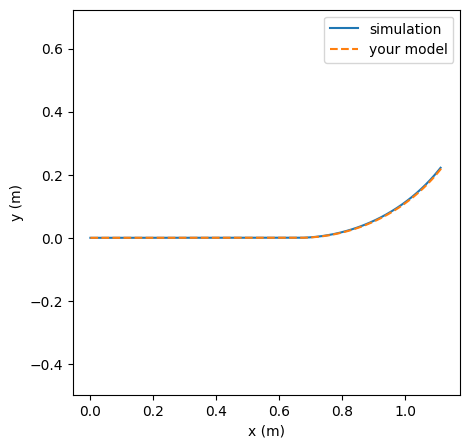

In [ ]:
plt.figure(figsize=(5, 5))
plt.plot(pose_sim[:, 1], pose_sim[:, 2], label="simulation")
plt.plot(path_model[:, 1], path_model[:, 2], "--", label="your model")
plt.axis("equal")
plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.legend()
plt.show()

In one sentence (5 points): does the simulated robot follow your model, and what would make the two drift apart?

*Hint:* the model assumes the wheels roll without slipping. When could a real or simulated wheel break that assumption?

*In the book:* the first paragraph of section 13.4 lists what makes wheel motion and chassis motion disagree ([chapter 13 PDF, page 34](https://artifacts.aegeanai.com/pdf/lynch-mr/wheeled-robots.pdf#page=34)).

**Answer.** The simulated path closely follows the kinematic model, while wheel slip, motor response, or imperfect wheel dimensions can make the two paths drift apart.

### Question 7 (15 points)

The simulation reports configurations in the world frame. To check the Background's claim that the robot never moves sideways, you need its velocity in the body frame.

**Task.** Write `world_to_body(phi, x_dot, y_dot)`. It returns $(v_x, v_y)$, the components of the world-frame velocity $(\dot x, \dot y)$ along the heading $\hat x_b = (\cos\phi, \sin\phi)$ and along the robot's left $\hat y_b = (-\sin\phi, \cos\phi)$. The inputs may be arrays, so use `np.cos` and `np.sin`.

*Hint:* the component of a vector along a unit vector is their dot product, so $v_x = \dot x\cos\phi + \dot y\sin\phi$. Write $v_y$ the same way with $\hat y_b$. The two checks test a robot facing $+\hat y$ and a robot facing $+\hat x$; work them out by hand first.

*In the book:* section 3.1 writes the body axes $\hat x_b$ and $\hat y_b$ in fixed-frame coordinates (Figure 3.3 and equations 3.2 and 3.3, [chapter 3 PDF, page 5](https://artifacts.aegeanai.com/pdf/lynch-mr/body-motions.pdf#page=5)) and introduces the planar twist $(\omega, v_x, v_y)$ ([page 9](https://artifacts.aegeanai.com/pdf/lynch-mr/body-motions.pdf#page=9)).

**Provided.** The check cell drives the simulated robot along an arc at $u_L = 3$, $u_R = 5$ rad/s. It estimates $(\dot\phi, \dot x, \dot y)$ from the simulated configurations, converts them to the body twist $(\omega, v_x, v_y)$ with your function, and compares the result with equation (1).

In [ ]:
def world_to_body(phi, x_dot, y_dot):
    v_x = x_dot * np.cos(phi) + y_dot * np.sin(phi)
    v_y = -x_dot * np.sin(phi) + y_dot * np.cos(phi)
    return v_x, v_y


In [ ]:
assert np.allclose(world_to_body(np.pi / 2, 0.0, 1.0), (1.0, 0.0)), "facing +y, moving along +y is straight ahead"
assert np.allclose(world_to_body(0.0, 0.0, 1.0), (0.0, 1.0)), "facing +x, moving along +y is toward the robot's left"

model, chassis, drives = build_turtlebot()
t_arc, pose_arc, _ = simulate(model, chassis, drives, lambda t: (3.0, 5.0), 4.0)
# estimate the rates of phi, x and y from how much the pose changes between frames.
# You don't need to fully understand these lines to answer the questions.
phi_arc = np.unwrap(pose_arc[:, 0])
omega_sim = np.gradient(phi_arc, t_arc)
v_x, v_y = world_to_body(phi_arc, np.gradient(pose_arc[:, 1], t_arc), np.gradient(pose_arc[:, 2], t_arc))
steady = slice(len(t_arc) // 4, None)  # skip the first second, while the motors spin up
v_model, omega_model = WHEEL_RADIUS * (3.0 + 5.0) / 2, WHEEL_RADIUS * (5.0 - 3.0) / (2 * HALF_SEPARATION)
print(f"turning rate:     model {omega_model:.3f} rad/s, simulation {omega_sim[steady].mean():.3f} rad/s")
print(f"forward speed:    model {v_model:.3f} m/s, simulation {v_x[steady].mean():.3f} m/s")
print(f"largest sideways speed in the simulation: {np.abs(v_y[steady]).max():.4f} m/s")
assert abs(omega_sim[steady].mean() - omega_model) < OMEGA_TOL, "measured and predicted turning rates should match"
assert abs(v_x[steady].mean() - v_model) < V_TOL, "measured and predicted forward speeds should match"
assert np.abs(v_y[steady]).max() < VBY_TOL, "the sideways body velocity should stay near zero"
print("passed")

turning rate:     model 0.230 rad/s, simulation 0.227 rad/s
forward speed:    model 0.132 m/s, simulation 0.131 m/s
largest sideways speed in the simulation: 0.0003 m/s
passed


In one sentence (5 points): which statement in the Background does the near-zero sideways velocity confirm, and what physical fact makes it true?

*Hint:* look back at the constraint you wrote in Question 2.

*In the book:* the no-slip constraint of the rolling coin in section 2.4 ([chapter 2 PDF, page 21](https://artifacts.aegeanai.com/pdf/lynch-mr/config-space.pdf#page=21)).

**Answer.** The near-zero sideways velocity confirms the Background's no-sideways-motion constraint, which is true because the wheels cannot slide along their axle.

### Question 8 (20 points)

Between two wheel-angle readings, the wheels turn by $\Delta\theta = (\Delta\theta_L, \Delta\theta_R)$. Equation (1) with wheel angles in place of wheel speeds gives the motion of the chassis over that step as a body twist (equation 13.34):

$$
\mathcal{V}_b = F\,\Delta\theta, \qquad
F = r\begin{bmatrix} -1/(2d) & 1/(2d) \\ 1/2 & 1/2 \\ 0 & 0 \end{bmatrix}.
$$

**Provided.** `displace(q, twist)` returns the configuration reached from `q` by following one constant body twist for one step, as in section 13.4.

**Task.** Write `odometry(q0, wheel_angles)`. `wheel_angles` has one row $(\theta_L, \theta_R)$ per reading. Start at `q0`. For each pair of consecutive readings, compute $\mathcal{V}_b = F\Delta\theta$ and apply `displace`. Return all configurations, including `q0`, as an array of shape `(N, 3)`.

*Hint:* `np.diff(wheel_angles, axis=0)` gives every $\Delta\theta$ at once, and `F @ delta` is the matrix product. Append each new configuration to `path`, and apply `displace` to the last one.

*In the book:* section 13.4 gives $F$ for a differential drive as equation 13.34 ([chapter 13 PDF, page 35](https://artifacts.aegeanai.com/pdf/lynch-mr/wheeled-robots.pdf#page=35)). `displace` computes equations 13.35 and 13.36 ([page 36](https://artifacts.aegeanai.com/pdf/lynch-mr/wheeled-robots.pdf#page=36)).

In [ ]:
def displace(q, twist):
    # move configuration q = (phi, x, y) by a constant body twist (omega, v_x, v_y) followed for one step.
    # You don't need to fully understand this function to answer the questions.
    w, vx, vy = twist
    if abs(w) < 1e-12:
        dx_b, dy_b = vx, vy
    else:
        dx_b = (vx * np.sin(w) + vy * (np.cos(w) - 1)) / w
        dy_b = (vy * np.sin(w) + vx * (1 - np.cos(w))) / w
    c, s = np.cos(q[0]), np.sin(q[0])
    return np.asarray(q, float) + np.array([w, c * dx_b - s * dy_b, s * dx_b + c * dy_b])

In [ ]:
def odometry(q0, wheel_angles):
    F = WHEEL_RADIUS * np.array([[-1 / (2 * HALF_SEPARATION), 1 / (2 * HALF_SEPARATION)], [0.5, 0.5], [0.0, 0.0]])
    path = [np.asarray(q0, float)]
    for delta in np.diff(wheel_angles, axis=0):
        twist = F @ delta
        path.append(displace(path[-1], twist))
    return np.array(path)


**Provided.** The check cell drives `test_course` again and runs your odometry on the simulated wheel angles.

In [ ]:
est = odometry([0.0, 0.0, 0.0], np.column_stack([np.linspace(0, 10, 11), np.linspace(0, 10, 11)]))
assert est.shape == (11, 3) and np.allclose(est[-1], [0.0, 10 * WHEEL_RADIUS, 0.0]), "10 rad on both wheels is 0.33 m straight ahead"
model, chassis, drives = build_turtlebot()
_, pose_course, angles_course = simulate(model, chassis, drives, test_course, 8.0)
est_course = odometry(pose_course[0], angles_course)
gap_odo = np.hypot(*(est_course[-1, 1:] - pose_course[-1, 1:]))
print(f"odometry ends {gap_odo:.3f} m from the true final position")
assert gap_odo < ODO_TOL, "odometry should end close to the true position on this short run"
print("passed")

odometry ends 0.004 m from the true final position
passed


**Provided.** On an 8 s drive, odometry stays within a few millimeters of the truth. The next cell drives a winding course for 60 s, alternating 10 s arcs to the left and to the right, and runs your odometry on it. The plots show both paths and the position error of odometry over time. On a CPU runtime the drive takes about five minutes.

In [ ]:
def winding_course(t):
    # wheel speeds (u_L, u_R) in rad/s: 10 s arcs, alternately to the left and to the right
    return (3.0, 5.0) if (t % 20.0) < 10.0 else (5.0, 3.0)


model, chassis, drives = build_turtlebot()
t_long, pose_long, angles_long = simulate(model, chassis, drives, winding_course, 60.0)
est_long = odometry(pose_long[0], angles_long)
error_long = np.hypot(est_long[:, 1] - pose_long[:, 1], est_long[:, 2] - pose_long[:, 2])
for seconds in (8, 20, 40, 60):
    print(f"odometry error after {seconds:2d} s: {100 * error_long[seconds * 60 - 1]:.1f} cm")

odometry error after  8 s: 0.7 cm
odometry error after 20 s: 2.7 cm
odometry error after 40 s: 5.3 cm
odometry error after 60 s: 7.8 cm


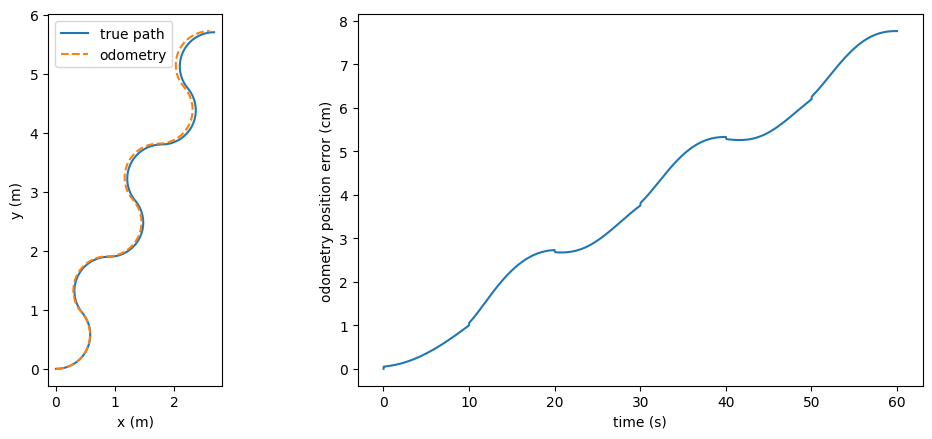

In [ ]:
fig, (ax_path, ax_error) = plt.subplots(1, 2, figsize=(11, 4.5))
ax_path.plot(pose_long[:, 1], pose_long[:, 2], label="true path")
ax_path.plot(est_long[:, 1], est_long[:, 2], "--", label="odometry")
ax_path.set_aspect("equal")
ax_path.set_xlabel("x (m)")
ax_path.set_ylabel("y (m)")
ax_path.legend()
ax_error.plot(np.arange(1, len(error_long) + 1) / 60, 100 * error_long)
ax_error.set_xlabel("time (s)")
ax_error.set_ylabel("odometry position error (cm)")
plt.tight_layout()
plt.show()

In one sentence (5 points): how does the odometry error change over the 60 s drive, and why?

*Hint:* compare with your answer to Question 5.

*In the book:* the first paragraph of section 13.4 ([chapter 13 PDF, page 34](https://artifacts.aegeanai.com/pdf/lynch-mr/wheeled-robots.pdf#page=34)).

**Answer.** The odometry error generally increases to about 7.8 cm by 60 s, with small temporary decreases. Because each step starts from the previous estimate, so small errors from wheel slip and integration are never removed and keep adding up.